Loading models from ./training_results_ensemble...
  - Loading model_0.pth
  - Loading model_1.pth
  - Loading model_2.pth
  - Loading model_3.pth
  - Loading model_4.pth
Successfully loaded 5 models for ensemble.
Scanning ./dataset_tri_RAD_Tensor_Corrected\real_test...
Total samples found: 4500 (Limit 500 per class)


Loading tensors: 100%|██████████| 4500/4500 [00:00<00:00, 13569.69it/s]


Running Inference...


Inferencing: 100%|██████████| 36/36 [00:02<00:00, 16.85it/s]



New Real Data Accuracy: 0.4822 (48.22%)
Confusion Matrix saved to: ./training_results_ensemble\new_real_data_cm.png


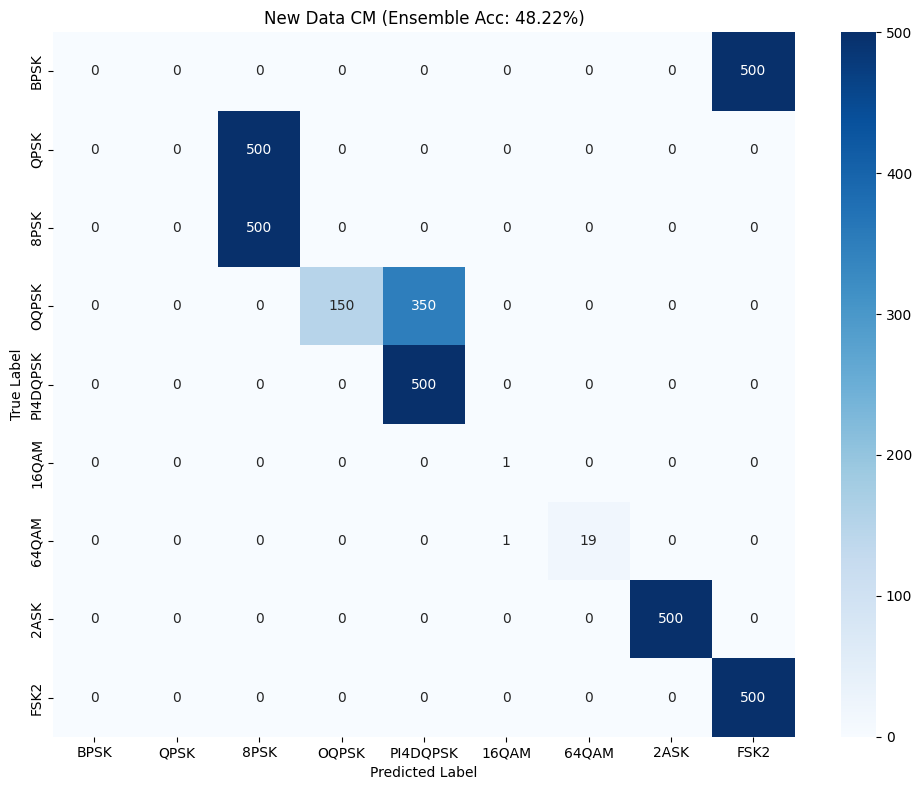

In [9]:
import os
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from tqdm import tqdm

# ================= 配置区域 =================
DEVICE = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

# [修改] 数据根目录 (确保这里面是你新生成的 .pt 文件)
DATASET_ROOT = "./dataset_tri_RAD_Tensor_Corrected" 
REAL_TEST_DIR = os.path.join(DATASET_ROOT, "real_test")

# [修改] 训练好的权重目录
RESULTS_DIR = "./training_results_ensemble" 

# 每个类别最大读取样本数
SAMPLES_LIMIT_PER_CLASS = 500

# 类别名称
CLASS_NAMES = [
    "BPSK", "QPSK", "8PSK", "OQPSK", "PI4DQPSK", 
    "16QAM", "32QAM", "64QAM", 
    "2ASK", "16APSK", "32APSK", "FSK2"
]
NUM_CLASSES = len(CLASS_NAMES)
BATCH_SIZE = 128

# ================= 模型定义 (保持与训练一致) =================
class TinyCNN(nn.Module):
    def __init__(self, num_classes):
        super(TinyCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256), nn.ReLU(),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

# ================= Dataset (带数量限制) =================
class RealDataset(Dataset):
    def __init__(self, root_dir, limit=500):
        self.data = []
        self.labels = []
        if not os.path.exists(root_dir): 
            print(f"Error: {root_dir} not found!")
            return
            
        print(f"Scanning {root_dir}...")
        files = []
        
        # 遍历每个类别文件夹
        for cls_name in CLASS_NAMES:
            d = Path(root_dir) / cls_name
            if d.exists():
                found = list(d.glob("*.pt"))
                
                # [关键修改] 数量截断
                if len(found) > limit:
                    found = found[:limit]
                
                files.extend([(p, CLASS_NAMES.index(cls_name)) for p in found])
        
        print(f"Total samples found: {len(files)} (Limit {limit} per class)")
        
        for p, label in tqdm(files, desc="Loading tensors"):
            try:
                # 加载 .pt 张量
                self.data.append(torch.load(p))
                self.labels.append(label)
            except Exception as e:
                print(f"Error loading {p}: {e}")

    def __len__(self): return len(self.data)
    def __getitem__(self, idx): return self.data[idx], self.labels[idx]

# ================= 推理主程序 =================
def main():
    # 1. 加载模型权重
    print(f"Loading models from {RESULTS_DIR}...")
    model_files = list(Path(RESULTS_DIR).glob("model_*.pth"))
    
    if len(model_files) == 0:
        print("No model files found! Please check RESULTS_DIR.")
        return
        
    models = []
    for p in model_files:
        print(f"  - Loading {p.name}")
        m = TinyCNN(NUM_CLASSES).to(DEVICE)
        try:
            m.load_state_dict(torch.load(p, map_location=DEVICE))
        except RuntimeError:
            print(f"    [Warn] Weights mismatch for {p.name}, skipping.")
            continue
        m.eval()
        models.append(m)
    
    if len(models) == 0:
        print("No valid models loaded.")
        return
        
    print(f"Successfully loaded {len(models)} models for ensemble.")

    # 2. 加载新数据 (带限制)
    ds = RealDataset(REAL_TEST_DIR, limit=SAMPLES_LIMIT_PER_CLASS)
    if len(ds) == 0: 
        print("No data found.")
        return
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False)

    # 3. 推理
    print("Running Inference...")
    y_true = []
    y_pred = []
    
    with torch.no_grad():
        for imgs, labels in tqdm(loader, desc="Inferencing"):
            imgs = imgs.to(DEVICE)
            y_true.extend(labels.numpy())
            
            # 集成推理 (Soft Voting)
            batch_outputs = []
            for m in models:
                out = m(imgs) # (Batch, 12)
                batch_outputs.append(out)
            
            # 取平均 (Logits 平均)
            avg_out = torch.stack(batch_outputs).mean(dim=0)
            _, preds = avg_out.max(1)
            y_pred.extend(preds.cpu().numpy())

    # 4. 结果统计
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    acc = np.mean(y_true == y_pred)
    
    print(f"\n================================")
    print(f"New Real Data Accuracy: {acc:.4f} ({acc*100:.2f}%)")
    print(f"================================")

    # 5. 绘制混淆矩阵
    existing_idx = sorted(list(set(y_true))) # 只显示存在的类别
    existing_names = [CLASS_NAMES[i] for i in existing_idx]
    
    if len(existing_idx) > 0:
        cm = confusion_matrix(y_true, y_pred, labels=existing_idx)
        
        plt.figure(figsize=(10, 8))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                    xticklabels=existing_names, yticklabels=existing_names)
        plt.title(f"New Data CM (Ensemble Acc: {acc:.2%})")
        plt.ylabel('True Label')
        plt.xlabel('Predicted Label')
        
        save_path = os.path.join(RESULTS_DIR, "new_real_data_cm.png")
        plt.tight_layout()
        plt.savefig(save_path)
        print(f"Confusion Matrix saved to: {save_path}")
        # 如果是在服务器无头模式下，这行可能会报错，可以注释掉
        try:
            plt.show()
        except:
            pass
    else:
        print("No labels found to plot confusion matrix.")

if __name__ == "__main__":
    main()